In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("imports ok")

imports ok


In [5]:
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(0)

print(df.shape)
print(df["Churn"].value_counts())

(7043, 21)
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [6]:
data = df.copy()
data["tenure_years"] = data["tenure"] / 12

service_cols = [
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies"
]
data["num_services"] = (data[service_cols] == "Yes").sum(axis=1)

print(data[["tenure", "tenure_years", "num_services"]].head(8))

   tenure  tenure_years  num_services
0       1      0.083333             1
1      34      2.833333             2
2       2      0.166667             2
3      45      3.750000             3
4       2      0.166667             0
5       8      0.666667             3
6      22      1.833333             2
7      10      0.833333             1


In [7]:
data["long_contract"] = data["Contract"].isin(["One year", "Two year"]).astype(int)

print(data[["Contract", "long_contract"]].head(10))
print(data["long_contract"].value_counts())

         Contract  long_contract
0  Month-to-month              0
1        One year              1
2  Month-to-month              0
3        One year              1
4  Month-to-month              0
5  Month-to-month              0
6  Month-to-month              0
7  Month-to-month              0
8  Month-to-month              0
9        One year              1
long_contract
0    3875
1    3168
Name: count, dtype: int64


In [8]:
print("Churn rate by long_contract:")
print(data.groupby("long_contract")["Churn"].value_counts(normalize=True))

print("\nAverage num_services by Churn:")
print(data.groupby("Churn")["num_services"].mean())

Churn rate by long_contract:
long_contract  Churn
0              No       0.572903
               Yes      0.427097
1              No       0.932449
               Yes      0.067551
Name: proportion, dtype: float64

Average num_services by Churn:
Churn
No     2.135292
Yes    1.768325
Name: num_services, dtype: float64


In [9]:
data["avg_charge_per_tenure"] = np.where(
    data["tenure"] > 0,
    data["TotalCharges"] / data["tenure"],
    data["MonthlyCharges"]
)

print(data[["tenure", "MonthlyCharges", "TotalCharges", "avg_charge_per_tenure"]].head(8))

   tenure  MonthlyCharges  TotalCharges  avg_charge_per_tenure
0       1           29.85         29.85              29.850000
1      34           56.95       1889.50              55.573529
2       2           53.85        108.15              54.075000
3      45           42.30       1840.75              40.905556
4       2           70.70        151.65              75.825000
5       8           99.65        820.50             102.562500
6      22           89.10       1949.40              88.609091
7      10           29.75        301.90              30.190000


In [10]:
y = data["Churn"]

X = data.drop(columns=["Churn", "customerID"])

print(X.shape)
print(X.columns.tolist())

(7043, 23)
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'tenure_years', 'num_services', 'long_contract', 'avg_charge_per_tenure']


In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

(5634, 23) (1409, 23)
Churn
No     0.734647
Yes    0.265353
Name: proportion, dtype: float64
Churn
No     0.734564
Yes    0.265436
Name: proportion, dtype: float64


In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

cat_cols = X_train.select_dtypes(include="object").columns
num_cols = X_train.select_dtypes(exclude="object").columns

preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", StandardScaler(), num_cols)
])

print("categorical:", cat_cols.tolist())
print("numeric:", num_cols.tolist())

categorical: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
numeric: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'tenure_years', 'num_services', 'long_contract', 'avg_charge_per_tenure']


In [13]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

pipe_log = Pipeline([
    ("prep", preprocess),
    ("model", LogisticRegression(max_iter=1000))
])

pipe_log.fit(X_train, y_train)
pred_log = pipe_log.predict(X_test)

print("Logistic accuracy:", accuracy_score(y_test, pred_log))
print(classification_report(y_test, pred_log, digits=3))

Logistic accuracy: 0.8069552874378992
              precision    recall  f1-score   support

          No      0.850     0.895     0.872      1035
         Yes      0.659     0.564     0.608       374

    accuracy                          0.807      1409
   macro avg      0.755     0.729     0.740      1409
weighted avg      0.800     0.807     0.802      1409



In [14]:
from sklearn.ensemble import RandomForestClassifier

pipe_rf = Pipeline([
    ("prep", preprocess),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

pipe_rf.fit(X_train, y_train)
pred_rf = pipe_rf.predict(X_test)

print("Random Forest accuracy:", accuracy_score(y_test, pred_rf))
print(classification_report(y_test, pred_rf, digits=3))

Random Forest accuracy: 0.7885024840312278
              precision    recall  f1-score   support

          No      0.833     0.891     0.861      1035
         Yes      0.626     0.505     0.559       374

    accuracy                          0.789      1409
   macro avg      0.729     0.698     0.710      1409
weighted avg      0.778     0.789     0.781      1409



In [16]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, accuracy_score

# Map target string labels to binary integers 0 and 1
y_train_encoded = y_train.map({"No": 0, "Yes": 1})
y_test_encoded = y_test.map({"No": 0, "Yes": 1})

pipe_xgb = Pipeline([
    ("prep", preprocess),
    ("model", XGBClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42,
        eval_metric="logloss"
    ))
])

pipe_xgb.fit(X_train, y_train_encoded)
pred_xgb_encoded = pipe_xgb.predict(X_test)

# Map predictions back to 'No' and 'Yes' for evaluation
pred_xgb = ["Yes" if pred == 1 else "No" for pred in pred_xgb_encoded]

print("XGBoost accuracy:", accuracy_score(y_test, pred_xgb))
print(classification_report(y_test, pred_xgb, digits=3))

XGBoost accuracy: 0.8019872249822569
              precision    recall  f1-score   support

          No      0.841     0.901     0.870      1035
         Yes      0.659     0.527     0.585       374

    accuracy                          0.802      1409
   macro avg      0.750     0.714     0.728      1409
weighted avg      0.792     0.802     0.794      1409



### Benchmark Results (Test Set)

* **Logistic Regression:** ~81% accuracy, ~56% recall for Churn (Yes)
* **Random Forest:** ~79% accuracy, ~51% recall for Churn (Yes)
* **XGBoost:** ~80% accuracy, ~53% recall for Churn (Yes)

**Conclusion:** Logistic Regression achieved the highest accuracy and the best recall for identifying at-risk customers on this split.

In [17]:
from sklearn.model_selection import GridSearchCV

pipe_log_tune = Pipeline([
    ("prep", preprocess),
    ("model", LogisticRegression(max_iter=2000))
])

param_grid = {
    "model__C": [0.01, 0.1, 1, 10],
    "model__penalty": ["l2"],
    "model__solver": ["lbfgs"]
}

grid = GridSearchCV(
    pipe_log_tune,
    param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
print("Best CV accuracy:", grid.best_score_)

Best params: {'model__C': 1, 'model__penalty': 'l2', 'model__solver': 'lbfgs'}
Best CV accuracy: 0.804932852745701


In [18]:
pred_tuned = grid.best_estimator_.predict(X_test)

print("Tuned logistic accuracy:", accuracy_score(y_test, pred_tuned))
print(classification_report(y_test, pred_tuned, digits=3))

Tuned logistic accuracy: 0.8069552874378992
              precision    recall  f1-score   support

          No      0.850     0.895     0.872      1035
         Yes      0.659     0.564     0.608       374

    accuracy                          0.807      1409
   macro avg      0.755     0.729     0.740      1409
weighted avg      0.800     0.807     0.802      1409



In [19]:
# names of columns after one-hot + scaled numerics
feature_names = grid.best_estimator_.named_steps["prep"].get_feature_names_out()

# coefficients for the Yes class
coefs = grid.best_estimator_.named_steps["model"].coef_[0]

importance = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefs
}).sort_values("coefficient", key=abs, ascending=False)

print(importance.head(15))


                                    feature  coefficient
11                 cat__InternetService_DSL    -0.654739
43                      num__MonthlyCharges    -0.653763
12         cat__InternetService_Fiber optic     0.632529
45                        num__tenure_years    -0.625947
42                              num__tenure    -0.625947
44                        num__TotalCharges     0.527847
34                   cat__Contract_Two year    -0.498922
47                       num__long_contract    -0.408341
35                 cat__PaperlessBilling_No    -0.328032
8                     cat__MultipleLines_No    -0.271723
18    cat__OnlineBackup_No internet service    -0.262591
13                  cat__InternetService_No    -0.262591
15  cat__OnlineSecurity_No internet service    -0.262591
27     cat__StreamingTV_No internet service    -0.262591
24     cat__TechSupport_No internet service    -0.262591


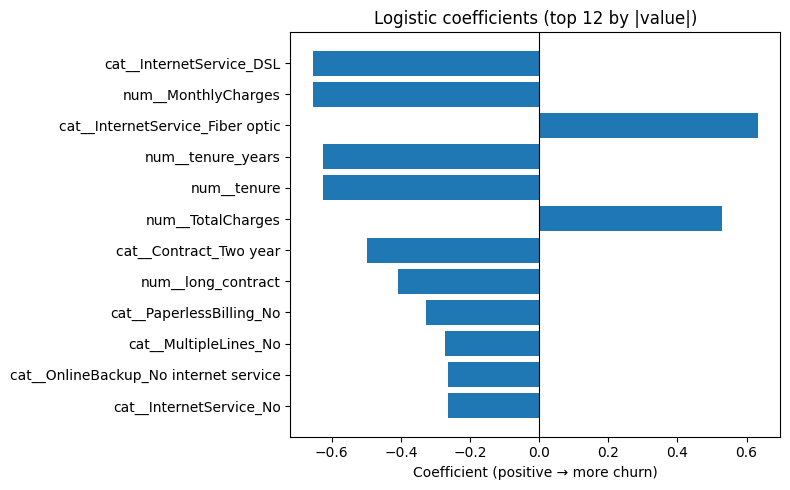

In [20]:
top = importance.head(12).iloc[::-1]  # reverse for nicer bar order

plt.figure(figsize=(8, 5))
plt.barh(top["feature"], top["coefficient"])
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Logistic coefficients (top 12 by |value|)")
plt.xlabel("Coefficient (positive → more churn)")
plt.tight_layout()
plt.show()

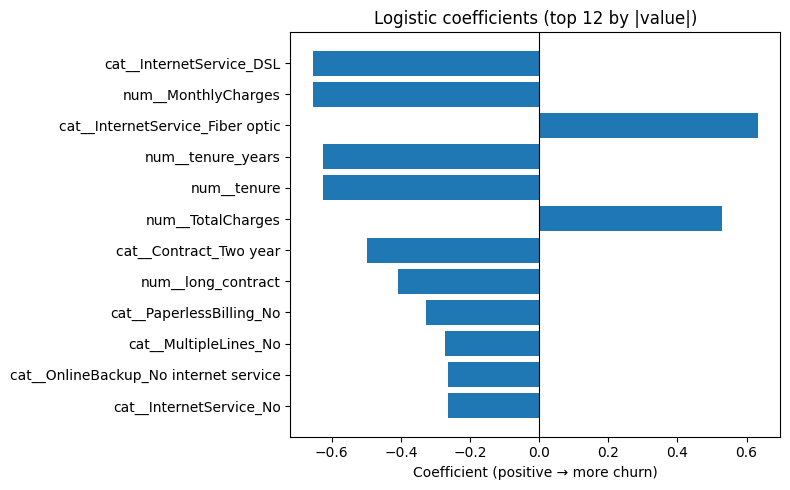

In [21]:
top = importance.head(12).iloc[::-1]  # reverse for nicer bar order

plt.figure(figsize=(8, 5))
plt.barh(top["feature"], top["coefficient"])
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Logistic coefficients (top 12 by |value|)")
plt.xlabel("Coefficient (positive → more churn)")
plt.tight_layout()
plt.show()

# Model card — Telco churn classifier

## Purpose
Predict whether a customer will churn (Yes/No) from account and service features.

## Data
- IBM Telco Customer Churn (~7043 customers, 21 original columns)
- Engineered: tenure_years, num_services, long_contract, avg_charge_per_tenure
- Train/test split 80/20, stratified

## Model
- Logistic Regression (best of Logistic / Random Forest / XGBoost on this split)
- One-hot encoding + standard scaling
- GridSearchCV over C; best C = 1

## Performance (test set)
- Accuracy: about 0.81 (baseline always-No about 0.74)
- Yes precision: about 0.66
- Yes recall: about 0.56
- Yes F1: about 0.61

## Limits and risks
- Misses many actual churners (recall ~0.56)
- Class imbalance: most customers stay
- Not proof of causation (e.g. contract type vs loyalty)
- Should not be the only input to retention actions

## Intended use
Research / learning benchmark, not production decisions without human review.